<a href="https://colab.research.google.com/github/imu-002/Music-player/blob/main/Skin_XAI_One_Click.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Skin-cancer XAI - one-click run
**Colab:** Runtime > Change runtime type > **T4 GPU**, then Runtime > **Run all**. Allow Google Drive when asked (so progress is saved).  
**Kaggle:** Settings > Accelerator GPU + **Internet ON**, then Run All.  
If any cell fails, copy the red error text and send it to Claude.

## 1. Setup

In [ ]:
import os, sys, subprocess, base64, zipfile, io, time
CFG = dict(
    EPOCHS=20,            # max epochs per run (early stopping is on)
    SEEDS=[0, 1, 2],
    ABLATION=False,       # True = also run the imbalance ablation (adds ~9 runs)
    N_PER_CLASS=10,       # test images per class for Grad-CAM / LIME
    LIME_SAMPLES=500,
    USE_DRIVE=True,       # Colab only: save results to Google Drive (resumable)
    DATA_ROOT=None,       # set a folder path only if HAM10000 is already somewhere
)
ON_COLAB = "google.colab" in sys.modules
ON_KAGGLE = os.path.exists("/kaggle")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "grad-cam", "lime", "thop", "onnx",
                "onnxruntime", "scikit-image", "opencv-python-headless", "pytest"], check=True)
CODE_B64 = (
    "..."
)
BASE = "/kaggle/working" if ON_KAGGLE else "/content"
zipfile.ZipFile(io.BytesIO(base64.b64decode(CODE_B64))).extractall(BASE)
os.chdir(f"{BASE}/skin_xai"); sys.path.insert(0, os.getcwd())
OUT_ROOT = f"{BASE}/skin_xai_run"
if ON_COLAB and CFG["USE_DRIVE"]:
    try:
        from google.colab import drive
        drive.mount("/content/drive"); OUT_ROOT = "/content/drive/MyDrive/skin_xai_run"
    except Exception as e:
        print("Drive not mounted, using local disk:", e)
RUNS, RES, WORK, RAW = f"{OUT_ROOT}/runs", f"{OUT_ROOT}/results", f"{BASE}/work", f"{BASE}/ham10000_raw"
for d in (RUNS, RES, WORK): os.makedirs(d, exist_ok=True)
import torch
print("GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
assert torch.cuda.is_available(), "No GPU. Runtime > Change runtime type > T4 GPU (Kaggle: Accelerator > GPU), then run again."
print("results folder:", OUT_ROOT)


Mounted at /content/drive
GPU: True Tesla T4
results folder: /content/drive/MyDrive/skin_xai_run


## 2. Data (finds it, or downloads it from the official Harvard Dataverse record)

In [ ]:
from src import data_setup as D
MANUAL = "/content/drive/MyDrive/skin_xai_data"      # optional: put manually downloaded HAM10000 files here
if os.path.isdir(MANUAL):
    D.unzip_all(MANUAL, RAW)
roots = [CFG["DATA_ROOT"]] if CFG["DATA_ROOT"] else []
roots += ["/kaggle/input", RAW, MANUAL]
found = D.find_existing(roots)
if not found:
    print("HAM10000 not found locally -> downloading from Harvard Dataverse (can take a while)")
    try:
        D.download_dataverse(RAW)
    except Exception as e:
        raise RuntimeError(
            "Automatic download failed (" + str(e) + ").\n"
            "MANUAL STEP: in your browser open the Harvard Dataverse record (search 'HAM10000 Harvard Dataverse', "
            "DOI 10.7910/DVN/DBW86T) and download: HAM10000_images_part_1.zip, HAM10000_images_part_2.zip, "
            "the metadata file (HAM10000_metadata), and HAM10000_segmentations_lesion_tschandl.zip. "
            "Put them in Google Drive > My Drive > skin_xai_data (create the folder), then Runtime > Run all again.")
    found = D.find_existing(roots)
elif not found["masks"]:
    print("no lesion masks found -> trying to download them")
    try:
        D.download_dataverse(RAW, kinds=("masks",)); found = D.find_existing(roots)
    except Exception as e:
        print("masks not available, IoU will be skipped:", e)
assert found, "Could not find HAM10000 after the download. See the manual step above."
META, RAW_IMG, RAW_MASK = D.stage_flat(found, f"{WORK}/flat")
info = D.verify(META, RAW_IMG, RAW_MASK)
print("masks available:", RAW_MASK is not None)


HAM10000 not found locally -> downloading from Harvard Dataverse (can take a while)
downloading images: HAM10000_images_part_1.zip (1367 MB)
downloading images: HAM10000_images_part_2.zip (1404 MB)
downloading metadata: HAM10000_metadata.csv (1 MB)
downloading masks: HAM10000_segmentations_lesion_tschandl.zip (11 MB)
{'metadata_rows': 10015, 'unique_lesions': 7470, 'images': 10015, 'masks': 10015, 'classes': ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']}
masks available: True


## 3. Preprocess + lesion-level splits + tests

In [ ]:
from src import pipeline as P
IMG, MASK = P.stage_prepare(META, RAW_IMG, RAW_MASK, WORK, CFG["SEEDS"])
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests"], capture_output=True, text=True)
print(r.stdout[-600:]); assert r.returncode == 0, "unit tests failed"


$ src.preprocess --images /kaggle/working/work/flat/images --out /kaggle/working/work/proc/images
$ src.preprocess --images /kaggle/working/work/flat/masks --out /kaggle/working/work/proc/masks --mask
$ src.splits --metadata /kaggle/working/work/metadata_clean.csv --out /kaggle/working/work/splits --seeds 0 1 2
.................                                                        [100%]
17 passed in 41.25s



## 4. Smoke test (about 5-10 minutes; stops here if something is broken)

In [ ]:
SMOKE = f"{WORK}/runs_smoke"
P.stage_train(WORK, SMOKE, IMG, [0], epochs=1, per_class=12, patience=1)
P.stage_explain(WORK, SMOKE, IMG, MASK, [0], models=["mobilenetv3"], n_per_class=2, lime_samples=50)
P.stage_report(SMOKE, f"{WORK}/results_smoke")
print("SMOKE TEST PASSED")


$ src.train --model resnet50 --seed 0 --epochs 1 --imbalance ce_weight --split_csv /kaggle/working/work/splits/split_seed0.csv --img_dir /kaggle/working/work/proc/images --out /kaggle/working/work/runs_smoke --batch_size 64 --patience 1 --workers 2 --per_class 12
   [resnet50 seed0 ce_weight] 0.5 min
$ src.train --model mobilenetv3 --seed 0 --epochs 1 --imbalance ce_weight --split_csv /kaggle/working/work/splits/split_seed0.csv --img_dir /kaggle/working/work/proc/images --out /kaggle/working/work/runs_smoke --batch_size 64 --patience 1 --workers 2 --per_class 12
   [mobilenetv3 seed0 ce_weight] 0.3 min
$ src.train --model efficientnet_lite --seed 0 --epochs 1 --imbalance ce_weight --split_csv /kaggle/working/work/splits/split_seed0.csv --img_dir /kaggle/working/work/proc/images --out /kaggle/working/work/runs_smoke --batch_size 64 --patience 1 --workers 2 --per_class 12
   [efficientnet_lite seed0 ce_weight] 0.2 min
$ src.explain --model mobilenetv3 --run /kaggle/working/work/runs_smok

## 5. Train: 3 models x 3 seeds (resumable - re-run this cell if the session stops)

In [ ]:
P.stage_train(WORK, RUNS, IMG, CFG["SEEDS"], epochs=CFG["EPOCHS"])

$ src.train --model resnet50 --seed 0 --epochs 20 --imbalance ce_weight --split_csv /kaggle/working/work/splits/split_seed0.csv --img_dir /kaggle/working/work/proc/images --out /content/drive/MyDrive/skin_xai_run/runs --batch_size 64 --patience 5 --workers 2
   [resnet50 seed0 ce_weight] 15.4 min
$ src.train --model mobilenetv3 --seed 0 --epochs 20 --imbalance ce_weight --split_csv /kaggle/working/work/splits/split_seed0.csv --img_dir /kaggle/working/work/proc/images --out /content/drive/MyDrive/skin_xai_run/runs --batch_size 64 --patience 5 --workers 2
   [mobilenetv3 seed0 ce_weight] 13.9 min
$ src.train --model efficientnet_lite --seed 0 --epochs 20 --imbalance ce_weight --split_csv /kaggle/working/work/splits/split_seed0.csv --img_dir /kaggle/working/work/proc/images --out /content/drive/MyDrive/skin_xai_run/runs --batch_size 64 --patience 5 --workers 2
   [efficientnet_lite seed0 ce_weight] 11.3 min
$ src.train --model resnet50 --seed 1 --epochs 20 --imbalance ce_weight --split_cs

## 6. Imbalance ablation (only if ABLATION=True)

In [ ]:
if CFG["ABLATION"]:
    P.stage_train(WORK, RUNS, IMG, CFG["SEEDS"], epochs=CFG["EPOCHS"], models=["mobilenetv3"],
                  imbalance=("none", "sampler", "both"))
else:
    print("skipped (ABLATION=False)")

skipped (ABLATION=False)


## 7. Efficiency benchmark (size, FLOPs, CPU latency)

In [ ]:
P.stage_benchmark(RES, onnx=True)

$ src.benchmark --out /content/drive/MyDrive/skin_xai_run/results/efficiency.csv --onnx


## 8. Explanations: Grad-CAM vs LIME, scored

In [ ]:
P.stage_explain(WORK, RUNS, IMG, MASK, CFG["SEEDS"], n_per_class=CFG["N_PER_CLASS"], lime_samples=CFG["LIME_SAMPLES"])

$ src.explain --model resnet50 --run /content/drive/MyDrive/skin_xai_run/runs/resnet50_ce_weight_seed0 --split_csv /kaggle/working/work/splits/split_seed0.csv --img_dir /kaggle/working/work/proc/images --n_per_class 10 --lime_samples 500 --seed 0 --mask_dir /kaggle/working/work/proc/masks
$ src.explain --model mobilenetv3 --run /content/drive/MyDrive/skin_xai_run/runs/mobilenetv3_ce_weight_seed0 --split_csv /kaggle/working/work/splits/split_seed0.csv --img_dir /kaggle/working/work/proc/images --n_per_class 10 --lime_samples 500 --seed 0 --mask_dir /kaggle/working/work/proc/masks
$ src.explain --model efficientnet_lite --run /content/drive/MyDrive/skin_xai_run/runs/efficientnet_lite_ce_weight_seed0 --split_csv /kaggle/working/work/splits/split_seed0.csv --img_dir /kaggle/working/work/proc/images --n_per_class 10 --lime_samples 500 --seed 0 --mask_dir /kaggle/working/work/proc/masks
$ src.explain --model resnet50 --run /content/drive/MyDrive/skin_xai_run/runs/resnet50_ce_weight_seed1 --s

## 9. Final tables + figure + bundle

$ src.make_report --runs /content/drive/MyDrive/skin_xai_run/runs --res /content/drive/MyDrive/skin_xai_run/results


,0,1,2
Model,ResNet-50 (baseline),MobileNetV3,EfficientNet-Lite
Seeds,3,3,3
Macro-F1,0.603 ± 0.041,0.650 ± 0.041,0.589 ± 0.021
Balanced acc.,0.694 ± 0.025,0.716 ± 0.011,0.673 ± 0.030
Accuracy,0.756 ± 0.013,0.791 ± 0.008,0.760 ± 0.014
Macro AUROC,0.932 ± 0.009,0.955 ± 0.003,0.948 ± 0.006
Melanoma recall,0.563 ± 0.035,0.512 ± 0.049,0.582 ± 0.067
Params (M),23.52,4.21,3.38
Size (MB),94.4,17.0,13.8
GMACs,4.13,0.22,0.37


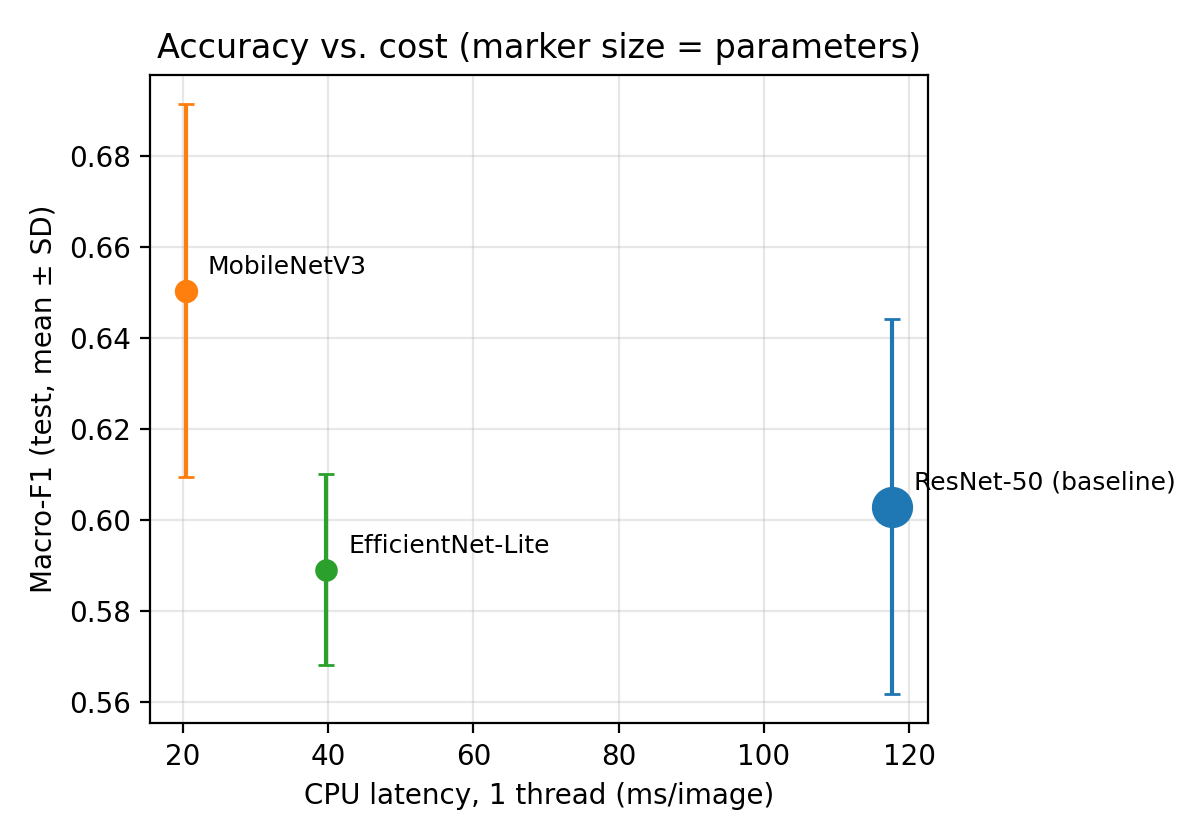

DONE. Send this file to Claude: /content/drive/MyDrive/skin_xai_run/results_bundle.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
P.stage_report(RUNS, RES)
import pandas as pd
from IPython.display import display, Image
t = pd.read_csv(f"{RES}/final_table.csv"); display(t.T)
if os.path.exists(f"{RES}/tradeoff.png"): display(Image(f"{RES}/tradeoff.png"))
# bundle small result files (no model checkpoints) so they can be sent back
bundle = f"{OUT_ROOT}/results_bundle.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for base in (RES, RUNS):
        for dp, dn, fn in os.walk(base):
            for f in fn:
                if f.endswith((".pt", ".npz")): continue
                p = os.path.join(dp, f); z.write(p, os.path.relpath(p, OUT_ROOT))
    for f in os.listdir(f"{WORK}/splits"): z.write(f"{WORK}/splits/{f}", f"splits/{f}")
print("DONE. Send this file to Claude:", bundle)
try:
    from google.colab import files; files.download(bundle)
except Exception: pass


### If the data download fails
Download manually from the Harvard Dataverse record (search: *HAM10000 Harvard Dataverse*, DOI 10.7910/DVN/DBW86T): the two image zips, the metadata file and the *segmentations_lesion_tschandl* zip. Unzip them anywhere, set `DATA_ROOT` in cell 1 to that folder, and run all again. IoU is skipped automatically if no masks are found.